# Exploring the iSarcasmEval data

Before writing any cleaning code, we want to actually look at the data. The things we want to
find out:

- What's in each file, and is anything missing or broken?
- Are there duplicates, and do any of them have different labels?
- How different is the test set from the training set?
- Are the author rephrasings usable for our rephrasing experiment?
- Do the "obvious" sarcasm cues (ALL CAPS, `!!`, "yeah right") actually show up more in
  sarcastic tweets?
- How well do humans do on this task?

This notebook only reads from `data/raw/`. Whatever we decide here gets implemented in
`src/data.py`. We look at the test set only to check data quality and how it differs from
train. Anything that could influence model design (like the cue counts in section 10) uses
the training file only.

Setup. Two helpers come up a lot below: `norm` turns a text into a comparison key (ignoring
whitespace and case), and `blank` catches NaN or empty strings.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)

# same color for each class in every plot
LABELS = {0: "non-sarcastic", 1: "sarcastic"}
COLORS = {0: "#2a78d6", 1: "#eb6834"}
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#52514e",
        "axes.labelcolor": "#0b0b0b",
        "text.color": "#0b0b0b",
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "axes.grid": True,
        "grid.color": "#e4e3df",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 110,
        "font.size": 10,
        "legend.frameon": False,
    }
)


def norm(s: pd.Series) -> pd.Series:
    """Comparison key: collapse whitespace (incl. \r\n), strip, lowercase."""
    return s.fillna("").str.replace(r"\s+", " ", regex=True).str.strip().str.lower()


def blank(s: pd.Series) -> pd.Series:
    """True for NaN or whitespace-only text."""
    return s.isna() | (s.fillna("").str.strip() == "")

## 1. What's in the files?

We have five files: the training set, the Task A test set (our main test set), the Task C test
pairs, and the human annotations for both test sets. First, what columns does each one have?

In [2]:
train = pd.read_csv(RAW / "train.En.csv")
test_a = pd.read_csv(RAW / "task_A_En_test.csv")
test_c = pd.read_csv(RAW / "task_C_En_test.csv")
human_a = pd.read_csv(RAW / "human_task_A_En.csv")
human_c = pd.read_csv(RAW / "human_task_C_En.csv")

FILES = {
    "train.En.csv": train,
    "task_A_En_test.csv": test_a,
    "task_C_En_test.csv": test_c,
    "human_task_A_En.csv": human_a,
    "human_task_C_En.csv": human_c,
}
pd.DataFrame({name: {"rows": len(df), "columns": list(df.columns)} for name, df in FILES.items()}).T

,rows,columns
train.En.csv,3468,"[Unnamed: 0, tweet, sarcastic, rephrase, sarcasm, irony, satire, understatement, overstatement, rhetorical..."
task_A_En_test.csv,1400,"[text, sarcastic]"
task_C_En_test.csv,200,"[text_0, text_1, sarcastic_id]"
human_task_A_En.csv,1400,"[text, sarcasm_ref, human_aggregated, #humans_sarcasm]"
human_task_C_En.csv,200,"[text_0, text_1, sarcastic_id_ref, human_aggregated, human_votes]"


In [3]:
for name, df in FILES.items():
    print(f"--- {name}")
    display(df.head(3))

--- train.En.csv


,Unnamed: 0,tweet,sarcastic,rephrase,sarcasm,irony,satire,understatement,overstatement,rhetorical_question
0,0,The only thing I got from college is a caffeine addiction,1,"College is really difficult, expensive, tiring, and I often question if a degree is worth the stress.",0.0,1.0,0.0,0.0,0.0,0.0
1,1,I love it when professors draw a big question mark next to my answer on an exam because I’m always like ye...,1,I do not like when professors don’t write out specific notes on my answers to exams.,1.0,0.0,0.0,0.0,0.0,0.0
2,2,Remember the hundred emails from companies when Covid started getting real? I’ve gotten three in regards t...,1,"I, at the bare minimum, wish companies actually cared about marginalized communities. At the max, that our...",0.0,1.0,0.0,0.0,0.0,0.0


--- task_A_En_test.csv


,text,sarcastic
0,"Size on the the Toulouse team, That pack is monstrous. \n\nI can't see a Welsh region ever winning this, M...",0
1,Pinball!,0
2,So the Scottish Government want people to get their booster shots so badly that the website doesn't even work,1


--- task_C_En_test.csv


,text_0,text_1,sarcastic_id
0,I see that your team played well today!,I'm sorry that your team didn't win yesterday.,0
1,"Anthony Taylor is such a fair referee, I wish he was put in charge of more chelsea matches",I hope Anthony Taylor is never put in charge of a Chelsea match again,0
2,"the weather is gloomy, just raining and dull.",What a glorious weather today,1


--- human_task_A_En.csv


,text,sarcasm_ref,human_aggregated,#humans_sarcasm
0,"Size on the the Toulouse team, That pack is monstrous. \r\n\r\nI can't see a Welsh region ever winning thi...",0,0,1
1,Pinball!,0,0,0
2,So the Scottish Government want people to get their booster shots so badly that the website doesn't even work,1,1,4


--- human_task_C_En.csv


,text_0,text_1,sarcastic_id_ref,human_aggregated,human_votes
0,I see that your team played well today!,I'm sorry that your team didn't win yesterday.,0,0,5
1,"Anthony Taylor is such a fair referee, I wish he was put in charge of more chelsea matches",I hope Anthony Taylor is never put in charge of a Chelsea match again,0,0,5
2,"the weather is gloomy, just raining and dull.",What a glorious weather today,1,1,5


Train has an unnamed first column. It looks like a leftover pandas index, so let's make sure:

In [4]:
idx = train["Unnamed: 0"]
print("Unnamed: 0 is exactly 0..n-1:", bool((idx == np.arange(len(train))).all()))

Unnamed: 0 is exactly 0..n-1: True


It is, so we can drop it. Also worth noting: train calls the text column `tweet`, while test
calls it `text`. None of the test files has an ID column, so we'll need to make our own IDs.

## 2. Missing values

A quick count of missing values per file:

In [5]:
for name, df in FILES.items():
    missing = df.isna().sum()
    print(
        f"{name}: "
        + (", ".join(f"{c}={n}" for c, n in missing[missing > 0].items()) or "no missing values")
    )

train.En.csv: tweet=1, rephrase=2601, sarcasm=2601, irony=2601, satire=2601, understatement=2601, overstatement=2601, rhetorical_question=2601
task_A_En_test.csv: no missing values
task_C_En_test.csv: no missing values
human_task_A_En.csv: no missing values
human_task_C_En.csv: no missing values


Train has a lot of missing values. We'd expect most of them to be in `rephrase` and the category
columns, which only exist for sarcastic tweets. Splitting by label to check:

In [6]:
cat_cols = ["sarcasm", "irony", "satire", "understatement", "overstatement", "rhetorical_question"]
g = train.groupby("sarcastic")
pd.DataFrame(
    {
        "rows": g.size(),
        "tweet missing/blank": g["tweet"].apply(lambda s: int(blank(s).sum())),
        "rephrase present": g["rephrase"].apply(lambda s: int(s.notna().sum())),
        "all 6 category labels present": g[cat_cols].apply(
            lambda d: int(d.notna().all(axis=1).sum())
        ),
    }
).rename(index=LABELS)

,rows,tweet missing/blank,rephrase present,all 6 category labels present
sarcastic,,,,
non-sarcastic,2601,1,0,0
sarcastic,867,0,867,867


That's right: `rephrase` and the categories are empty for exactly the non-sarcastic rows, so
those aren't really missing. That leaves one tweet that's actually missing:

In [7]:
print("Blank/NaN rows in train:")
display(train[blank(train["tweet"])])
print("Blank/NaN texts in test A:", int(blank(test_a["text"]).sum()))

Blank/NaN rows in train:


,Unnamed: 0,tweet,sarcastic,rephrase,sarcasm,irony,satire,understatement,overstatement,rhetorical_question
1062,1062,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Blank/NaN texts in test A: 0


Row 1062 has no text at all (it's labelled non-sarcastic), so we'll drop it. Test has no
missing text.

## 3. How imbalanced is it?

In [8]:
def label_table(s: pd.Series) -> pd.DataFrame:
    c = s.value_counts().sort_index()
    return pd.DataFrame({"count": c, "share": (c / c.sum()).round(3)}).rename(index=LABELS)


pd.concat(
    {"train": label_table(train["sarcastic"]), "test A": label_table(test_a["sarcastic"])}, axis=1
)

train       test A       
              count share  count  share
sarcastic                              
non-sarcastic  2601  0.75   1200  0.857
sarcastic       867  0.25    200  0.143

Train is 25% sarcastic, but test is only about 14% (0.143). That's a bigger gap than we
expected. Our validation set will come out of train, so it will have the 25% ratio. A threshold
we tune on validation might therefore predict "sarcastic" too often on test, which is something
to watch when we look at test results.

It also means accuracy isn't very useful here. Predicting "not sarcastic" for everything
already gets 85.7% accuracy on test (0.857), but its sarcastic-class F1 is 0. That's why the
task is scored with F1 on the sarcastic class.

## 4. Sarcasm categories

Sarcastic train tweets also have expert labels for the type of ironic speech. We don't need them
for Subtask A, but they could be useful for error analysis later.

In [9]:
sarc = train[train["sarcastic"] == 1]
display(sarc[cat_cols].sum().astype(int).sort_values(ascending=False).to_frame("n_tweets"))
sarc[cat_cols].sum(axis=1).astype(int).value_counts().sort_index().rename_axis(
    "n_categories"
).to_frame("n_tweets")

,n_tweets
sarcasm,713
irony,155
rhetorical_question,101
overstatement,40
satire,25
understatement,10


,n_tweets
n_categories,
1,692
2,173
3,2


Most are plain "sarcasm" (713 of 867), and some tweets have two or three categories. A few
categories are tiny (only 10 understatements), so we shouldn't read much into per-category
results.

## 5. Tweet length

Do sarcastic tweets tend to be longer or shorter? And are train and test tweets similar in
length?

In [10]:
def lengths(text: pd.Series, label: pd.Series, split: str) -> pd.DataFrame:
    keep = ~blank(text)
    t = text[keep]
    return pd.DataFrame(
        {
            "split": split,
            "label": label[keep].map(LABELS),
            "chars": t.str.len(),
            "words": t.str.split().str.len(),
        }
    )


L = pd.concat(
    [
        lengths(train["tweet"], train["sarcastic"], "train"),
        lengths(test_a["text"], test_a["sarcastic"], "test A"),
    ]
)
L.groupby(["split", "label"]).agg(
    n=("words", "size"),
    words_median=("words", "median"),
    words_mean=("words", "mean"),
    words_max=("words", "max"),
    chars_median=("chars", "median"),
    chars_mean=("chars", "mean"),
    chars_max=("chars", "max"),
).round(1)

n  words_median  words_mean  words_max  chars_median  chars_mean  chars_max
split  label                                                                                        
test A non-sarcastic  1200          14.0        15.4        128          75.0        82.5        613
       sarcastic       200          20.0        22.3        109         107.0       119.1        533
train  non-sarcastic  2600          17.0        19.0         61          91.0       105.7        365
       sarcastic       867          16.0        18.3         57          90.0       100.1        397

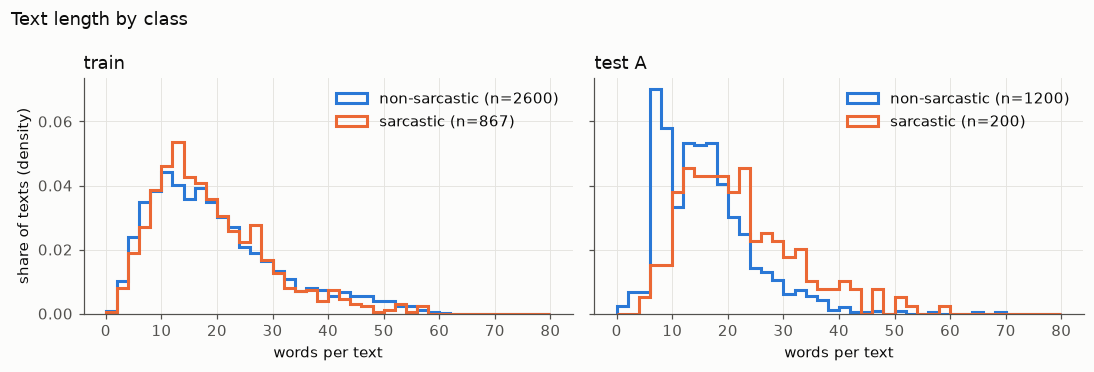

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True, sharey=True)
bins = np.arange(0, 81, 2)
for ax, split in zip(axes, ["train", "test A"], strict=True):
    for y, name in LABELS.items():
        w = L[(L["split"] == split) & (L["label"] == name)]["words"]
        ax.hist(
            w,
            bins=bins,
            density=True,
            histtype="step",
            linewidth=2,
            color=COLORS[y],
            label=f"{name} (n={len(w)})",
        )
    ax.set_title(split, loc="left")
    ax.set_xlabel("words per text")
    ax.legend()
axes[0].set_ylabel("share of texts (density)")
fig.suptitle("Text length by class", x=0.01, ha="left")
fig.tight_layout()
plt.show()

In train the two classes look almost the same (median 17 vs 16 words). In test they don't:
sarcastic texts are clearly longer (median 20 vs 14). So a model can't learn a length signal from
train, but one does exist in test. That's another train/test difference to keep in mind.

Here are the extremes:

In [12]:
t = train.loc[~blank(train["tweet"]), ["tweet", "sarcastic"]]
t = t.assign(words=t["tweet"].str.split().str.len())
print("Shortest train tweets:")
display(t.nsmallest(8, "words"))
print("Longest train tweets:")
display(t.nlargest(3, "words"))

Shortest train tweets:

,tweet,sarcastic,words
788,"""friends""",1,1
1186,https://t.co/jpgi5N4U9C,0,1
1814,hi,0,1
2337,thunderstorms😍😍,0,1
2469,MTCHEWWWWWWWW,0,1
2621,hello,0,1
183,@PlayStationUK Nice,1,2
295,we happy!!!!!!!!!!,1,2


Longest train tweets:


,tweet,sarcastic,words
1585,I remember when I was a kid how I used to troll my dad. \nI’d be watching a film on sky movies and then wh...,0,61
1198,if anyone wants to count their shirts for me… let me know. need some validation. having a crisis because i...,0,58
1586,"Knocked on a door to deliver a parcel, waited 30secs then I see the parcel had a safeplace so went to the ...",0,58


Some tweets have hardly any content: a bare link, "hi", "hello". `"friends"` (with the quotes)
is labelled sarcastic, which shows that sometimes the sarcasm can't be recovered from the text
alone. Nothing to clean here, though: these are real examples.

## 6. Duplicates

We checked for duplicates two ways: exact matches, and matches after ignoring whitespace and case.

In [13]:
def duplicate_groups(text: pd.Series, label: pd.Series) -> pd.DataFrame:
    df = pd.DataFrame({"text": text, "label": label, "key": norm(text)})[~blank(text)]
    d = df[df["key"].duplicated(keep=False)]
    groups = d.groupby("key").agg(
        n_rows=("label", "size"),
        labels=("label", lambda s: sorted(s.tolist())),
        example=("text", "first"),
    )
    groups["conflicting_labels"] = groups["labels"].map(lambda labels: len(set(labels)) > 1)
    return groups.sort_values(["conflicting_labels", "n_rows"], ascending=False).reset_index(
        drop=True
    )


valid_train = train[~blank(train["tweet"])]
print("train  exact-duplicate rows:     ", int(valid_train["tweet"].duplicated(keep=False).sum()))
train_dups = duplicate_groups(train["tweet"], train["sarcastic"])
print(
    "train  normalized-duplicate rows:",
    int(train_dups["n_rows"].sum()),
    "in",
    len(train_dups),
    "groups",
)
print(
    "train  groups with conflicting labels:",
    int(train_dups["conflicting_labels"].sum()),
    "covering",
    int(train_dups.loc[train_dups["conflicting_labels"], "n_rows"].sum()),
    "rows",
)
train_dups

train  exact-duplicate rows:      20
train  normalized-duplicate rows: 20 in 9 groups
train  groups with conflicting labels: 5 covering 12 rows


,n_rows,labels,example,conflicting_labels
0,4,"[0, 0, 0, 1]","@AsdaServiceTeam imagine your delivery being 2 hours late, and imagine calling up your service team only f...",True
1,2,"[0, 1]","@AlexShawESPN @robwishart @GNev2 Does he order 11 at once and drink each one at just over 5 minutes, OR do...",True
2,2,"[0, 1]",if i saw a capybara in person id probably throw up,True
3,2,"[0, 1]",Replace Pelosi #Nancy,True
4,2,"[0, 1]","Whoever’s toddler ass sprayed the entire toilet backstage, I hope you stub your toe and bite your tongue r...",True
5,2,"[0, 0]",@kevinabstract ye,False
6,2,"[0, 0]",going to class! https://t.co/VgCWGl9YTG,False
7,2,"[0, 0]",Great effort @Patriots We'll get em all next year,False
8,2,"[0, 0]",Omg flashbacks to emma blackery girl balls merch and the fact that i spent money on it,False


There are 20 duplicated rows in 9 groups, and ignoring whitespace and case doesn't find any
more. The bigger problem is that 5 of those groups have conflicting labels. The Asda tweet, for
example, appears four times: once as sarcastic and three times as not. We can't know which label
is right, so we'll drop those 12 rows completely. For the other 4 groups (same label) we'll keep
one copy.

In [14]:
test_dups = duplicate_groups(test_a["text"], test_a["sarcastic"])
print(
    "test A normalized-duplicate rows:",
    int(test_dups["n_rows"].sum()),
    "in",
    len(test_dups),
    "groups;",
    "conflicting:",
    int(test_dups["conflicting_labels"].sum()),
)
test_dups

test A normalized-duplicate rows: 12 in 6 groups; conflicting: 0


,n_rows,labels,example,conflicting_labels
0,2,"[0, 0]",I see all the reasons Mark has put forward and they are well explained but you need to ask yourself what i...,False
1,2,"[0, 0]",I'm a bit biased but I have to say this was fantastic. The talent in the young people on our island is ama...,False
2,2,"[0, 0]",Im just gonna go out there and say it… Chas and Dave are underrated in my opinion.,False
3,2,"[0, 0]",Norwich need to score whilst they’re on top.,False
4,2,"[0, 0]",One of my favorite stops in London!,False
5,2,"[0, 0]",So stoked to see them tonight,False


Test has 6 pairs of identical texts, all non-sarcastic. We'll leave test alone, since it's the
official test set.

Is anything in both train and test?

In [15]:
tr_keys = pd.DataFrame({"key": norm(train["tweet"]), "train_label": train["sarcastic"]})[
    ~blank(train["tweet"])
]
te_keys = pd.DataFrame(
    {"key": norm(test_a["text"]), "test_label": test_a["sarcastic"], "text": test_a["text"]}
)
overlap = te_keys.merge(tr_keys, on="key")
print("Test A texts that also appear in train (normalized):", overlap["key"].nunique())
overlap[["text", "train_label", "test_label"]]

Test A texts that also appear in train (normalized): 1


,text,train_label,test_label
0,I love my friends,0,0


Just one text ("I love my friends", non-sarcastic in both), so that's fine.

One consequence for the split: duplicate texts need to stay on the same side of train/val.
Otherwise the model would see some validation tweets during training.

## 7. URLs, mentions and other noise

Twitter data is usually messy, so we counted a few patterns in train and test: links,
@mentions, hashtags, HTML entities, line breaks, broken characters and emoji.

In [16]:
EMOJI = "[\U0001f300-\U0001faff☀-➿]"
PATTERNS = {
    "URL": r"https?://\S+",
    "@mention": r"@\w+",
    "#hashtag": r"#\w+",
    "HTML entity (&amp; &lt; &gt; &quot; &#NN;)": r"&(?:amp|lt|gt|quot|#\d+);",
    "newline \\n": r"\n",
    "carriage return \\r": r"\r",
    "U+FFFD replacement char": "�",
    "mojibake (â€ or Ã+char)": r"â€|Ã.",
    "emoji (approx. ranges)": EMOJI,
}
tr_text = train.loc[~blank(train["tweet"]), "tweet"]
te_text = test_a["text"]
noise = pd.DataFrame(
    {
        "train n": {k: int(tr_text.str.contains(p, regex=True).sum()) for k, p in PATTERNS.items()},
        "train %": {
            k: round(100 * tr_text.str.contains(p, regex=True).mean(), 1)
            for k, p in PATTERNS.items()
        },
        "test n": {k: int(te_text.str.contains(p, regex=True).sum()) for k, p in PATTERNS.items()},
        "test %": {
            k: round(100 * te_text.str.contains(p, regex=True).mean(), 1)
            for k, p in PATTERNS.items()
        },
    }
)
noise

,train n,train %,test n,test %
URL,269,7.8,0,0.0
@mention,554,16.0,1,0.1
#hashtag,380,11.0,1,0.1
HTML entity (&amp; &lt; &gt; &quot; &#NN;),90,2.6,19,1.4
newline \n,232,6.7,91,6.5
carriage return \r,0,0.0,0,0.0
U+FFFD replacement char,0,0.0,3,0.2
mojibake (â€ or Ã+char),0,0.0,0,0.0
emoji (approx. ranges),668,19.3,298,21.3


The big thing here: URLs, @mentions and hashtags are all over train (7.8%, 16.0% and 11.0% of
tweets) but almost completely absent from test (0.0%, 0.1% and 0.1%). We don't know how the test
set was collected, so we can't say why. It matters especially for TF-IDF, which could learn
specific @handles or link tokens that never appear in test. We'll replace URLs with `<URL>`
and mentions with `<USER>`.

There's no mojibake, and emoji are about as common in train as in test (19.3% vs 21.3%).

Some examples of the HTML entities and the broken characters:

In [17]:
def examples(text: pd.Series, pattern: str, n: int = 3) -> list[str]:
    return text[text.str.contains(pattern, regex=True)].head(n).tolist()


print(
    "HTML entities (train):",
    *examples(tr_text, PATTERNS["HTML entity (&amp; &lt; &gt; &quot; &#NN;)"]),
    sep="\n  ",
)
print("U+FFFD (test):", *examples(te_text, "�"), sep="\n  ")
print("URLs (train):", *examples(tr_text, PATTERNS["URL"]), sep="\n  ")

HTML entities (train):
  So in other news I just held the door open for Bam Adebayo &amp; then I fell down the stairs &amp; I think I broke my finger.. ya I'm THAT smooth
  i love jumping on zoom meetings where everyone is talking about their kids &amp; i'm stuffing my face with taco bell
  I recovered a repressed memory today of working at @kumandgo in high school 13 years ago &amp; having to answer the phone as “we go all out at Kum &amp; Go, this is Shelby. How can I help you?” And the prank calls that led to. Pretty sure K&amp;G owe me therapy.
U+FFFD (test):
  Temp: 5.7�C. Humidity 71% Rain today 1.2 mm. Barometer 999.0 hPa, Rising quickly. Wind 9 mph W, WindRun 78.0 mi, Gust 12 mph.
  Temp: 8.8�C. Humidity 90% Rain today 1.8 mm. Barometer 989.6 hPa, Falling quickly. Wind 5 mph SSE, WindRun 121.3 mi, Gust 7 mph.
  Temp: 9.8�C. Humidity 91% Rain today 1.5 mm. Barometer 1015.5 hPa, Falling slowly. Wind 3 mph SSE, WindRun 40.9 mi, Gust 8 mph.
URLs (train):
  ANY PENSIONER AND 4 YEAR 

`&amp;` should just be `&`, so we'll unescape those. The broken `�` characters are in three
weather-bot tweets where the degree sign got lost. That's how they are in the original data, so
we'll leave them.

The human annotation file didn't match the test texts exactly, which made us check line endings
in every file:

In [18]:
for name, df in FILES.items():
    text_cols = [c for c in df.columns if df[c].dtype != "int64" and df[c].dtype != "float64"]
    n = sum(int(df[c].fillna("").str.contains("\r").sum()) for c in text_cols)
    print(f"{name}: {n} text cells containing \\r")

train.En.csv: 0 text cells containing \r
task_A_En_test.csv: 0 text cells containing \r
task_C_En_test.csv: 0 text cells containing \r
human_task_A_En.csv: 91 text cells containing \r
human_task_C_En.csv: 0 text cells containing \r


Only the human annotation file has Windows line endings (`\r\n`). Train and test don't, so
there's nothing to fix in the data itself. We just have to ignore whitespace when matching the
human labels to test (section 11).

Since hashtags are so common in train, we also wanted to make sure none of them give the label
away. Older sarcasm datasets were often collected by searching for tags like #sarcasm or #not.

In [19]:
tags = tr_text.str.findall(r"#\w+").explode().dropna().str.lower()
print("distinct hashtags in train:", tags.nunique(), "| total uses:", len(tags))
print("most common:", tags.value_counts().head(8).to_dict())
for tag in ["#sarcasm", "#sarcastic", "#not", "#irony", "#jk"]:
    hit = tr_text.str.lower().str.contains(tag + r"\b", regex=True)
    tag_labels = train.loc[hit[hit].index, "sarcastic"].value_counts().to_dict()
    print(f"{tag:<11} tweets: {int(hit.sum())}  labels: {tag_labels}")
print("test texts with a hashtag:", te_text[te_text.str.contains(r"#\w+", regex=True)].tolist())
print("test texts with an @mention:", te_text[te_text.str.contains(r"@\w+", regex=True)].tolist())

distinct hashtags in train: 541 | total uses: 604
most common: {'#trump': 6, '#bbccricket': 5, '#cricket': 4, '#ghostoftsushima': 4, '#wtf1': 3, '#loveisland': 3, '#nffc': 3, '#lineofduty': 3}
#sarcasm    tweets: 0  labels: {}
#sarcastic  tweets: 1  labels: {1: 1}
#not        tweets: 0  labels: {}
#irony      tweets: 0  labels: {}
#jk         tweets: 0  labels: {}
test texts with a hashtag: ['#stressingaboutcookingchristmasdinner']
test texts with an @mention: ['hello @dwp, i am upset because i have to choose between affording bills and food because you lowered payments that were already low']


Only one tweet uses #sarcastic, and none use #sarcasm or #not. Most hashtags are just topics
(#trump, #cricket, ...), so we'll keep them as they are.

## 8. The rephrasings

Every sarcastic train tweet has a rephrasing, written by its author, that says the same thing
without sarcasm. Our rephrasing experiment depends on these, so we wanted to see what they look
like.

In [20]:
rep = pd.DataFrame(
    {
        "tweet": sarc["tweet"],
        "rephrase": sarc["rephrase"],
        "tweet_words": sarc["tweet"].fillna("").str.split().str.len(),
        "rephrase_words": sarc["rephrase"].fillna("").str.split().str.len(),
    }
)
rep[["tweet_words", "rephrase_words"]].describe().round(1)

,tweet_words,rephrase_words
count,867.0,867.0
mean,18.3,13.8
std,10.2,9.0
min,1.0,1.0
25%,11.0,8.0
50%,16.0,12.0
75%,24.0,17.0
max,57.0,98.0


Rephrasings are a bit shorter on average (13.8 vs 18.3 words). Let's look at the very short
ones, and check whether any are just copies of the tweet:

In [21]:
print("Rephrasings with <= 2 words:")
display(rep[rep["rephrase_words"] <= 2])
print("Rephrasings identical to their tweet (normalized):")
display(rep[norm(rep["tweet"]) == norm(rep["rephrase"])])

Rephrasings with <= 2 words:


,tweet,rephrase,tweet_words,rephrase_words
78,"if you see me crying in the self-service car wash in my rosati’s uniform, no you didn’t ❤️",No.,18,1
128,@igreen95 thx for the play by play,"""Sounds interesting!""",7,2
154,@sonofsama1 @Santandave1 you’re trash,You’re terrible,4,2
273,"@benshapiro it’s true, every time my little cousins put on their masks they choke to death and have to be ...",No.,26,1
372,Synthwave communities really love pessimism don't they haha\nAny upbeat energy and people get upset at ya,yes,17,1
547,@trpalomo Those boots must be tasty for how much they're choking on 'em 💀,No.,14,1
590,my computer does this fun thing now where it shakes in a way that exactly replicates what happens to my vi...,Yes,30,1
702,Wishing all the birthday sex on @laurabora620 today 🎂 https://t.co/JtP0FCvo9R,Happy Birthday,10,2


Rephrasings identical to their tweet (normalized):


,tweet,rephrase,tweet_words,rephrase_words


Eight rephrasings are two words or shorter, and some of them aren't really rephrasings: "No.",
"Yes" and "yes" read more like replies to the tweet. We'll keep them in the data but flag them
in the rephrasing experiment. None of the rephrasings is a copy of its tweet.

Do any rephrasings show up as tweets elsewhere?

In [22]:
rep_keys = set(norm(sarc["rephrase"])) - {""}
print("Rephrasings that also appear as a train tweet:", len(rep_keys & set(norm(train["tweet"]))))
print("Rephrasings that also appear in test A:       ", len(rep_keys & set(norm(test_a["text"]))))

Rephrasings that also appear as a train tweet: 0
Rephrasings that also appear in test A:        0


No, so they can't leak into test.

## 9. Task C pairs hiding in the test set

Task C provides sarcastic/rephrasing pairs from the test period. We wondered whether those texts
also appear in the Task A test set.

In [23]:
sar_c = test_c.apply(lambda r: r[f"text_{r['sarcastic_id']}"], axis=1)
reph_c = test_c.apply(lambda r: r[f"text_{1 - r['sarcastic_id']}"], axis=1)
a_labels = (
    pd.DataFrame({"key": norm(test_a["text"]), "label": test_a["sarcastic"]})
    .groupby("key")["label"]
    .agg(set)
)

sar_in_a = norm(sar_c).map(a_labels)
reph_in_a = norm(reph_c).map(a_labels)
pd.Series(
    {
        "Task C pairs": len(test_c),
        "sarcastic text found in Task A": int(sar_in_a.notna().sum()),
        "  ... labelled 1 there": int(
            sar_in_a.map(lambda s: s == {1}, na_action="ignore").fillna(False).sum()
        ),
        "rephrase found in Task A": int(reph_in_a.notna().sum()),
        "  ... labelled 0 there": int(
            reph_in_a.map(lambda s: s == {0}, na_action="ignore").fillna(False).sum()
        ),
        "both texts of the pair in Task A": int((sar_in_a.notna() & reph_in_a.notna()).sum()),
        "Task C texts found in train (tweet or rephrase)": int(
            (
                norm(sar_c).isin(set(norm(train["tweet"])))
                | norm(reph_c).isin(set(norm(train["tweet"])) | rep_keys)
            ).sum()
        ),
    }
).to_frame("count")

,count
Task C pairs,200
sarcastic text found in Task A,91
... labelled 1 there,91
rephrase found in Task A,91
... labelled 0 there,91
both texts of the pair in Task A,91
Task C texts found in train (tweet or rephrase),0


They do, for 91 of the 200 pairs: the sarcastic tweet (labelled 1) and its rephrasing (labelled
0) are both separate rows in test A. The other 109 pairs aren't in test A, and none of them are in
train.

This is interesting for us. Test A contains 91 non-sarcastic texts that mean the same thing as a
sarcastic test text, and a model that relies on topic words should struggle with those. For the
rephrasing experiment on test, we'll use all 200 Task C pairs.

## 10. Do the usual sarcasm cues work here?

For the rule-based model we planned to use the usual sarcasm cues: exclamation marks, ALL CAPS,
intensifiers like "totally", interjections like "yeah right", and so on. Before building it, we
wanted to see whether these cues actually show up more often in sarcastic tweets.

We use only the training file here, so the test set doesn't influence how we design the model.
This does include tweets that will end up in our validation set, but we're only choosing which
cues to try. The weights and the threshold will still be tuned on validation. URLs and
@mentions are removed first, so handles like @NHS don't count as ALL CAPS.

In [24]:
INTENSIFIERS = ["so", "totally", "absolutely", "really", "very", "literally", "such"]
INTERJECTIONS = ["oh great", "yeah right", "wow", "sure", "thanks a lot", "great job"]


def any_word(words: list[str]) -> str:
    """Case-insensitive regex matching any of ``words`` as whole words."""
    return r"(?i)\b(?:" + "|".join(words) + r")\b"


CUES = {
    "'!!' or more": r"!{2,}",
    "'?!' or '!?'": r"\?!|!\?",
    "ellipsis ... or …": r"\.{3,}|…",
    "question mark": r"\?",
    "ALL-CAPS word (2+ letters)": r"\b[A-Z]{2,}\b",
    "double quotes": r"[\"“”]",
    f"intensifier ({'/'.join(INTENSIFIERS)})": any_word(INTENSIFIERS),
    f"interjection ({'/'.join(INTERJECTIONS)})": any_word(INTERJECTIONS),
    "emoji (approx.)": EMOJI,
}
cue_text = valid_train["tweet"].str.replace(r"https?://\S+|@\w+", " ", regex=True)
cue_label = valid_train["sarcastic"]
rates = pd.DataFrame(
    {
        name: {
            LABELS[y]: cue_text[cue_label == y].str.contains(p, regex=True).mean() for y in LABELS
        }
        for name, p in CUES.items()
    }
).T
rates["sarcastic / non-sarcastic"] = (rates["sarcastic"] / rates["non-sarcastic"]).round(2)
rates = rates.sort_values("sarcastic / non-sarcastic")
(
    rates.assign(**{c: (100 * rates[c]).round(1) for c in LABELS.values()}).rename(
        columns={"non-sarcastic": "non-sarcastic %", "sarcastic": "sarcastic %"}
    )
)

,non-sarcastic %,sarcastic %,sarcastic / non-sarcastic
ALL-CAPS word (2+ letters),13.7,9.9,0.72
intensifier (so/totally/absolutely/really/very/literally/such),21.1,18.0,0.85
'?!' or '!?',0.7,0.7,1.00
double quotes,5.8,7.0,1.20
'!!' or more,2.6,3.2,1.23
emoji (approx.),18.2,22.5,1.24
ellipsis ... or …,4.1,5.7,1.37
question mark,9.7,14.4,1.49
interjection (oh great/yeah right/wow/sure/thanks a lot/great job),1.3,3.8,2.83


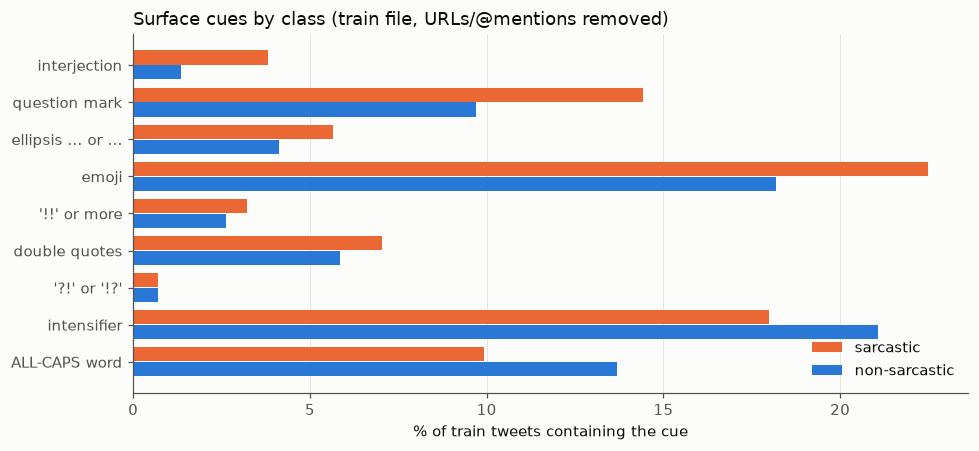

In [25]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ypos = np.arange(len(rates))
h = 0.38
for i, (y, name) in enumerate(LABELS.items()):
    ax.barh(ypos + (i - 0.5) * (h + 0.02), 100 * rates[name], height=h, color=COLORS[y], label=name)
ax.set_yticks(ypos, [n.split(" (")[0] for n in rates.index])
ax.set_xlabel("% of train tweets containing the cue")
ax.set_title("Surface cues by class (train file, URLs/@mentions removed)", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", reverse=True)  # legend order matches the bars
fig.tight_layout()
plt.show()

This surprised us. ALL CAPS and intensifiers are actually *more* common in non-sarcastic tweets
(13.7% vs 9.9%, and 21.1% vs 18.0%), and `?!` is equally rare in both. The cues that do lean
sarcastic are either weak or rare. Interjections are 2.83 times more frequent in sarcastic tweets,
but they appear in only 3.8% of them. Question marks (1.49x) and ellipses (1.37x) are only
somewhat more common.

So we expect the rule-based model to struggle. That's relevant to our research question: it
suggests that intended sarcasm in this dataset usually isn't marked by obvious surface cues.

These regexes are rough. ALL CAPS also catches acronyms like UK, and the emoji ranges don't cover
everything. We also haven't looked at sentiment contrast yet; that will be part of the
rule-based model itself.

## 11. How do humans do?

The test set was also labelled by five outside annotators. First we checked that this file lines
up with test A:

In [26]:
print(
    "Rows aligned with test A, exact text:      ", bool((human_a["text"] == test_a["text"]).all())
)
print(
    "Rows aligned with test A, normalized text: ",
    bool((norm(human_a["text"]) == norm(test_a["text"])).all()),
)
print("Rows whose text differs only in whitespace:", int((human_a["text"] != test_a["text"]).sum()))
print(
    "sarcasm_ref equals test A label:           ",
    bool((human_a["sarcasm_ref"] == test_a["sarcastic"]).all()),
)
print(
    "human_aggregated == (#humans_sarcasm >= 3):",
    bool((human_a["human_aggregated"] == (human_a["#humans_sarcasm"] >= 3).astype(int)).all()),
)

Rows aligned with test A, exact text:       False
Rows aligned with test A, normalized text:  True
Rows whose text differs only in whitespace: 91
sarcasm_ref equals test A label:            True
human_aggregated == (#humans_sarcasm >= 3): True


It lines up row by row once whitespace is ignored (91 rows differ only in their line endings).
The reference labels match, and `human_aggregated` is just a majority vote (3 or more of 5).

How did the annotators vote, split by what the author said?

In [27]:
votes = pd.crosstab(human_a["#humans_sarcasm"], human_a["sarcasm_ref"].map(LABELS))
votes.index.name = "# of 5 annotators saying sarcastic"
votes

sarcasm_ref,non-sarcastic,sarcastic
# of 5 annotators saying sarcastic,,
0,598,7
1,287,13
2,151,19
3,95,25
4,47,37
5,22,99


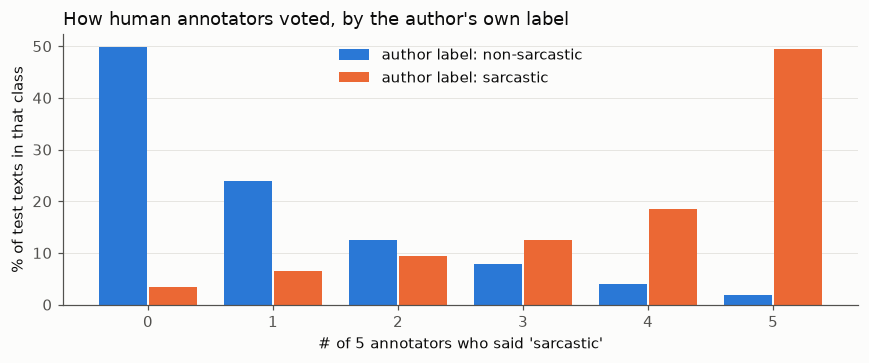

In [28]:
share = votes / votes.sum()
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(share))
w = 0.38
for i, (y, name) in enumerate(LABELS.items()):
    ax.bar(
        x + (i - 0.5) * (w + 0.02),
        100 * share[name],
        width=w,
        color=COLORS[y],
        label=f"author label: {name}",
    )
ax.set_xticks(x, share.index)
ax.set_xlabel("# of 5 annotators who said 'sarcastic'")
ax.set_ylabel("% of test texts in that class")
ax.set_title("How human annotators voted, by the author's own label", loc="left")
ax.grid(axis="x", visible=False)
ax.legend()
fig.tight_layout()
plt.show()

Only 99 of the 200 sarcastic tweets got all five votes. 7 sarcastic tweets weren't caught by
anyone, while 22 non-sarcastic tweets were called sarcastic by all five annotators. These vote
counts give us a natural way to split test into easy and hard examples later.

How well does the majority vote do against the authors' labels?

In [29]:
y_true, y_hum = human_a["sarcasm_ref"], human_a["human_aggregated"]
human_metrics = {
    "F1 (sarcastic)": f1_score(y_true, y_hum, pos_label=1),
    "precision (sarcastic)": precision_score(y_true, y_hum, pos_label=1),
    "recall (sarcastic)": recall_score(y_true, y_hum, pos_label=1),
    "accuracy": accuracy_score(y_true, y_hum),
    "F1 (macro)": f1_score(y_true, y_hum, average="macro"),
}
display(pd.Series(human_metrics).round(4).to_frame("human majority vote vs author label (test A)"))
pd.DataFrame(
    confusion_matrix(y_true, y_hum), index=["true 0", "true 1"], columns=["human 0", "human 1"]
)

,human majority vote vs author label (test A)
F1 (sarcastic),0.6133
precision (sarcastic),0.4954
recall (sarcastic),0.8050
accuracy,0.8550
F1 (macro),0.7621


,human 0,human 1
true 0,1036,164
true 1,39,161


Humans get an F1 of 0.6133 on the sarcastic class. Recall is decent (0.805), but precision is
low (0.4954): the annotators flagged 164 non-sarcastic texts as sarcastic. So even people are far
from perfect at this task.

For comparison, here's the simplest possible baseline, predicting "sarcastic" for everything:

In [30]:
always_1 = np.ones(len(test_a), dtype=int)
print(
    "Always-sarcastic F1 (sarcastic) on test A:",
    round(f1_score(test_a["sarcastic"], always_1, pos_label=1), 4),
)

Always-sarcastic F1 (sarcastic) on test A: 0.25


That gives 0.25, which every model we build needs to beat.

Last, Task C: given a tweet and its rephrasing, can humans tell which one is sarcastic?

In [31]:
print(
    "Task C: sarcastic_id_ref equals test C label:",
    bool((human_c["sarcastic_id_ref"] == test_c["sarcastic_id"]).all()),
)
print(
    "Task C: human majority accuracy:",
    round(float((human_c["human_aggregated"] == human_c["sarcastic_id_ref"]).mean()), 4),
)
human_c["human_votes"].value_counts().sort_index().rename_axis(
    "votes for majority label (of 5)"
).to_frame("pairs")

Task C: sarcastic_id_ref equals test C label: True
Task C: human majority accuracy: 0.97


,pairs
votes for majority label (of 5),
3,14
4,33
5,153


They get 97% right, so spotting sarcasm is much easier when you can compare a tweet with its
plain version.

## 12. What we're taking into `data.py`

Everything we decided above, in one table. The numbers are computed from the cells above.

In [32]:
conf = train_dups[train_dups["conflicting_labels"]]
same = train_dups[~train_dups["conflicting_labels"]]
html_key = "HTML entity (&amp; &lt; &gt; &quot; &#NN;)"
cr_human = int(human_a["text"].str.contains("\r").sum())
cr_key = "carriage return \\r"
cr_train_test = int(noise.loc[cr_key, "train n"] + noise.loc[cr_key, "test n"])
n_short_rep = int((rep["rephrase_words"] <= 2).sum())
n_same_rep = int((norm(rep["tweet"]) == norm(rep["rephrase"])).sum())
n_c_in_a = int((sar_in_a.notna() & reph_in_a.notna()).sum())
always_1_f1 = f1_score(test_a["sarcastic"], always_1, pos_label=1)
share_tr = train["sarcastic"].mean()
share_te = test_a["sarcastic"].mean()


def pct(key: str) -> str:
    return f"{noise.loc[key, 'train %']}% / {noise.loc[key, 'test %']}%"


summary = pd.DataFrame(
    [
        (
            "train rows / test A rows",
            f"{len(train)} / {len(test_a)}",
            "Split validation off train (stratified, fixed seed).",
        ),
        (
            "sarcastic share (train / test A)",
            f"{share_tr:.3f} / {share_te:.3f}",
            "Keep in mind that a val-tuned threshold may not transfer to test.",
        ),
        ("train 'Unnamed: 0' column", "row index only", "Drop it and make our own ids."),
        (
            "blank or NaN texts (train / test A)",
            f"{int(blank(train['tweet']).sum())} / {int(blank(test_a['text']).sum())}",
            "Drop, and log how many.",
        ),
        (
            "train duplicates with conflicting labels",
            f"{len(conf)} groups, {int(conf['n_rows'].sum())} rows",
            "Drop all of them.",
        ),
        (
            "train duplicates with the same label",
            f"{len(same)} groups, {int(same['n_rows'].sum())} rows",
            "Keep one copy each.",
        ),
        (
            "test A duplicates",
            f"{len(test_dups)} groups, {int(test_dups['n_rows'].sum())} rows",
            "Leave test as published.",
        ),
        (
            "test A texts also in train",
            f"{overlap['key'].nunique()}",
            "Keep, but log it. Keep identical texts on one side of the train/val split.",
        ),
        ("texts with URLs (train / test A)", pct("URL"), "Replace with <URL>."),
        ("texts with @mentions (train / test A)", pct("@mention"), "Replace with <USER>."),
        (
            "texts with hashtags (train / test A)",
            pct("#hashtag"),
            "Keep as is; none give the label away.",
        ),
        (
            "texts with HTML entities (train / test A)",
            f"{noise.loc[html_key, 'train n']} / {noise.loc[html_key, 'test n']}",
            "Unescape (&amp; -> &).",
        ),
        (
            "cells with \\r: train+test / human file",
            f"{cr_train_test} / {cr_human}",
            "Nothing to clean; ignore whitespace when matching human labels.",
        ),
        (
            "U+FFFD characters (test A)",
            f"{noise.loc['U+FFFD replacement char', 'test n']}",
            "Leave as is (it's in the original data).",
        ),
        (
            "emoji, punctuation, capitalization",
            "kept",
            "Don't strip; they're possible sarcasm cues.",
        ),
        (
            "rephrasings with <= 2 words / copies of the tweet",
            f"{n_short_rep} / {n_same_rep}",
            "Keep; flag the short ones in the rephrasing experiment.",
        ),
        (
            "Task C pairs with both texts in test A",
            f"{n_c_in_a} of {len(test_c)}",
            "Use all Task C pairs for the test-side rephrasing experiment.",
        ),
        (
            "human majority vote F1 (sarcastic), test A",
            f"{human_metrics['F1 (sarcastic)']:.4f}",
            "Report as a reference point.",
        ),
        (
            "always-sarcastic F1 (sarcastic), test A",
            f"{always_1_f1:.4f}",
            "Report as the trivial baseline.",
        ),
    ],
    columns=["finding", "numbers", "what we'll do"],
)

with pd.option_context("display.max_colwidth", None):
    display(summary)

,finding,numbers,what we'll do
0,train rows / test A rows,3468 / 1400,"Split validation off train (stratified, fixed seed)."
1,sarcastic share (train / test A),0.250 / 0.143,Keep in mind that a val-tuned threshold may not transfer to test.
2,train 'Unnamed: 0' column,row index only,Drop it and make our own ids.
3,blank or NaN texts (train / test A),1 / 0,"Drop, and log how many."
4,train duplicates with conflicting labels,"5 groups, 12 rows",Drop all of them.
5,train duplicates with the same label,"4 groups, 8 rows",Keep one copy each.
6,test A duplicates,"6 groups, 12 rows",Leave test as published.
7,test A texts also in train,1,"Keep, but log it. Keep identical texts on one side of the train/val split."
8,texts with URLs (train / test A),7.8% / 0.0%,Replace with <URL>.
9,texts with @mentions (train / test A),16.0% / 0.1%,Replace with <USER>.
